<h1 style="text-align: center;"><b><u>ML Assignment 2 — Steel Plates Faults: training 5 classifiers</u></b></h1>

**Name:** Chaitanya Naga Pramila R

**Student ID:** 2025NS04102

In [13]:
!pip install -q ucimlrepo tabulate
import os, joblib
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef)
SEED = 42
TARGET = "Fault"
os.makedirs("model", exist_ok=True)

## 1. Load data

In [14]:
from ucimlrepo import fetch_ucirepo
ds = fetch_ucirepo(id=198)
X = ds.data.features.copy()
Y = ds.data.targets.copy()
print(X.shape, Y.shape)

(1941, 27) (1941, 7)


## 2. Collapse the 7 one-hot columns into one target

In [15]:
assert (Y.sum(axis=1) == 1).all(), "Every row should have exactly one fault label"
y = Y.idxmax(axis=1).rename(TARGET)
print(y.value_counts())
print("Missing values:", X.isnull().sum().sum())

Fault
Other_Faults    673
Bumps           402
K_Scratch       391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: count, dtype: int64
Missing values: 0


## 3. Split and scale

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
scaler = StandardScaler().fit(X_train)
Xtr, Xte = scaler.transform(X_train), scaler.transform(X_test)

## 4. Train and evaluate

In [17]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": CalibratedClassifierCV(SVC(random_state=SEED), ensemble=False),
}
rows = []
for name, clf in models.items():
    clf.fit(Xtr, y_train)
    pred = clf.predict(Xte)
    proba = clf.predict_proba(Xte)
    rows.append({
        "ML Model Name": name,
        "Accuracy": accuracy_score(y_test, pred),
        "AUC": roc_auc_score(y_test, proba, multi_class="ovr", average="weighted"),
        "Precision": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1": f1_score(y_test, pred, average="weighted", zero_division=0),
        "MCC": matthews_corrcoef(y_test, pred),
    })
    joblib.dump(clf, f"model/{name.lower().replace(' ', '_')}.pkl")
results = pd.DataFrame(rows).round(4)
results

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.7275,0.9066,0.7329,0.7275,0.7277,0.6487
1,Decision Tree,0.7429,0.8283,0.7455,0.7429,0.7429,0.6688
2,kNN,0.7275,0.8941,0.7318,0.7275,0.7245,0.6548
3,Naive Bayes,0.6093,0.8840,0.6700,0.6093,0.5883,0.5484
4,Support Vector Machine,0.7506,0.8974,0.7578,0.7506,0.7521,0.6769


## 5. Save artefacts and README table

In [18]:
joblib.dump(scaler, "model/scaler.pkl")
joblib.dump({"features": list(X.columns), "target": TARGET}, "model/meta.pkl")
pd.concat([X_test, y_test], axis=1).to_csv("test_data.csv", index=False)
results.to_csv("model/results.csv", index=False)
print(results.to_markdown(index=False))

| ML Model Name          |   Accuracy |    AUC |   Precision |   Recall |     F1 |    MCC |
|:-----------------------|-----------:|-------:|------------:|---------:|-------:|-------:|
| Logistic Regression    |     0.7275 | 0.9066 |      0.7329 |   0.7275 | 0.7277 | 0.6487 |
| Decision Tree          |     0.7429 | 0.8283 |      0.7455 |   0.7429 | 0.7429 | 0.6688 |
| kNN                    |     0.7275 | 0.8941 |      0.7318 |   0.7275 | 0.7245 | 0.6548 |
| Naive Bayes            |     0.6093 | 0.884  |      0.67   |   0.6093 | 0.5883 | 0.5484 |
| Support Vector Machine |     0.7506 | 0.8974 |      0.7578 |   0.7506 | 0.7521 | 0.6769 |


## 6. Confusion matrices (all 5 models)

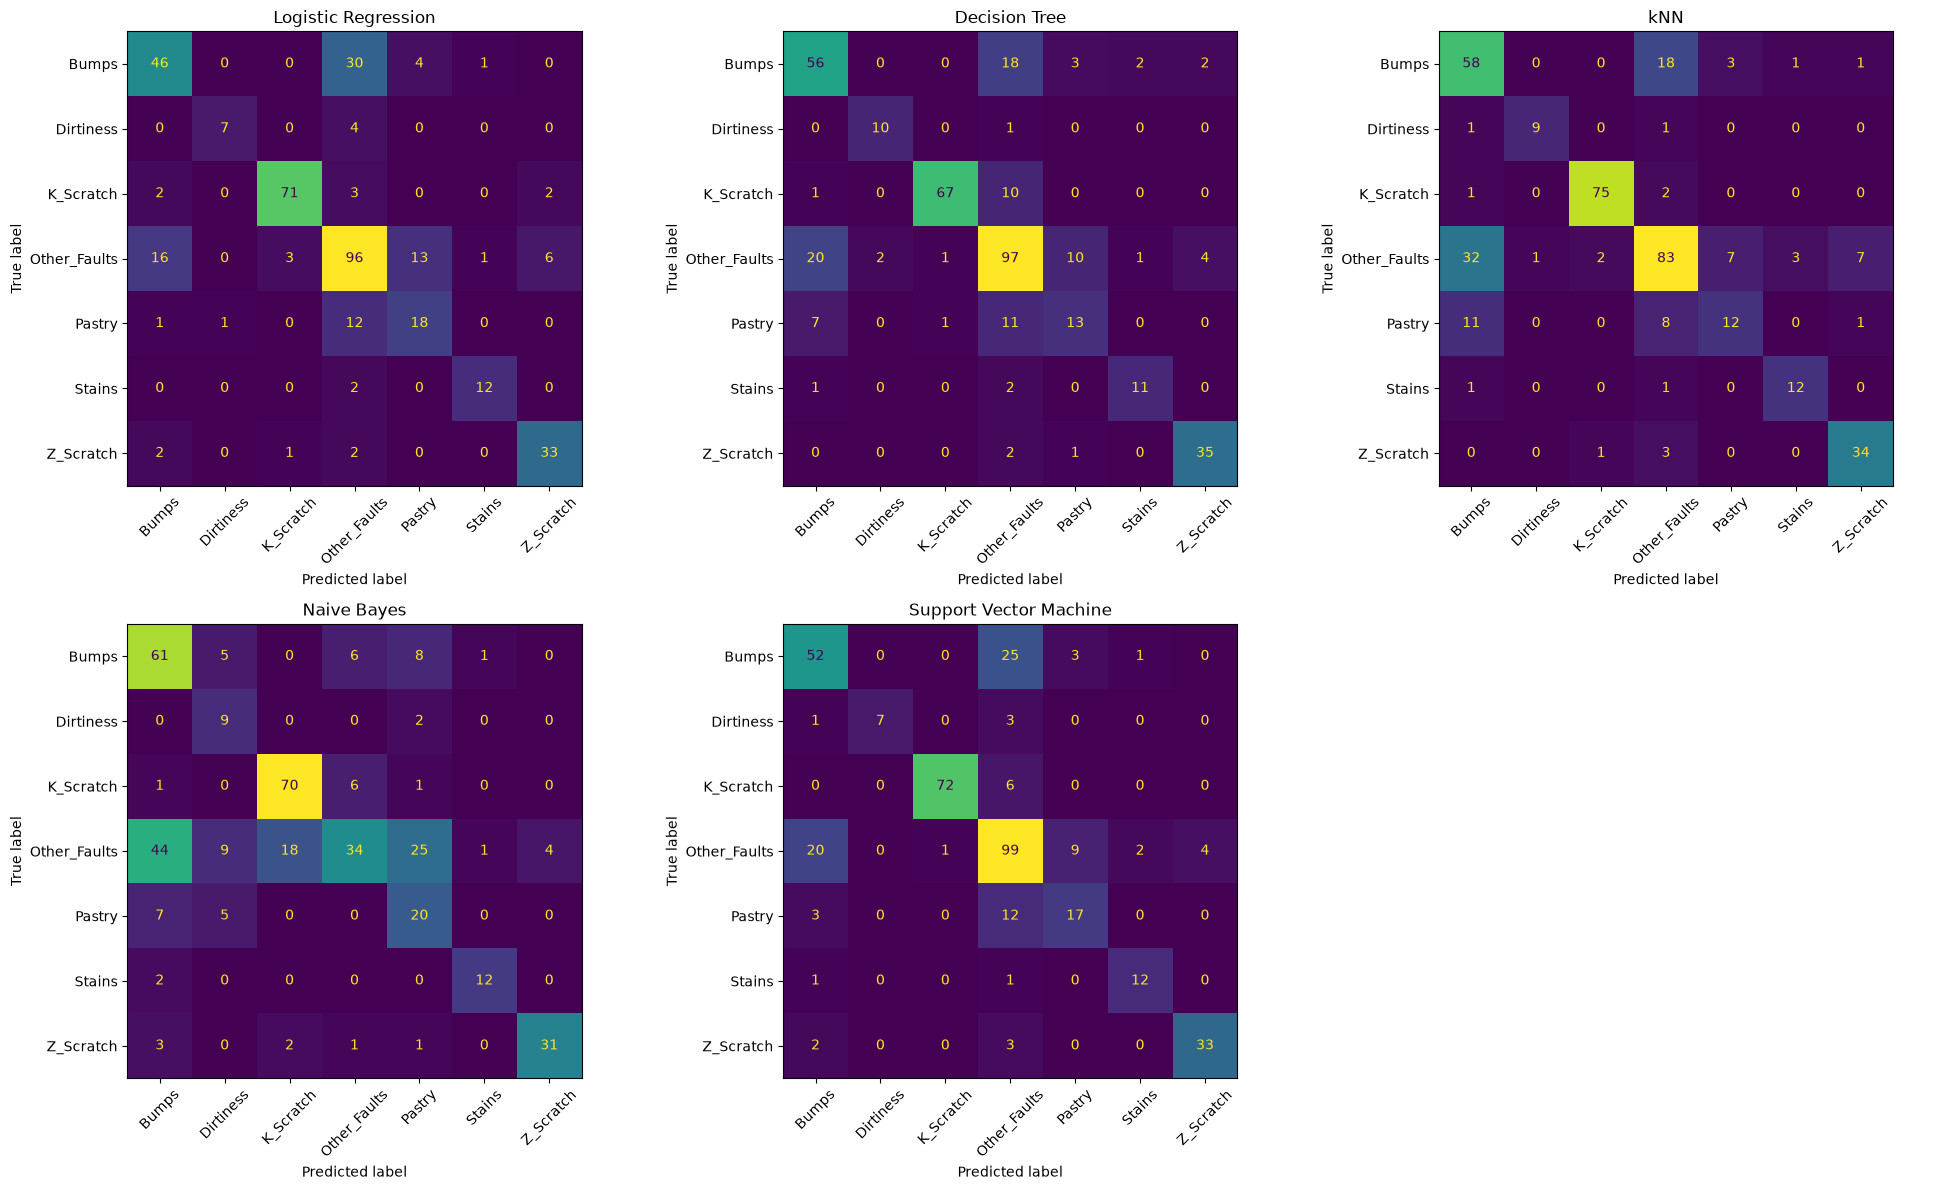

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

labels = sorted(y.unique())
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for ax, (name, clf) in zip(axes.ravel(), models.items()):
    cm = confusion_matrix(y_test, clf.predict(Xte), labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, xticks_rotation=45, colorbar=False)
    ax.set_title(name)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig("model/confusion_matrices.png", dpi=120)
plt.show()

## 7. Per-class performance (which faults are hard to detect?)

In [20]:
per_class_recall = {}
for name, clf in models.items():
    rep = classification_report(y_test, clf.predict(Xte), output_dict=True, zero_division=0)
    per_class_recall[name] = {c: rep[c]["recall"] for c in labels}
per_class_recall = pd.DataFrame(per_class_recall).round(3)
print("Recall per fault class:")
display(per_class_recall)
print("\nFull report for the best model (SVM):")
print(classification_report(y_test, models["Support Vector Machine"].predict(Xte), zero_division=0))

Recall per fault class:


,Logistic Regression,Decision Tree,kNN,Naive Bayes,Support Vector Machine
Bumps,0.568,0.691,0.716,0.753,0.642
Dirtiness,0.636,0.909,0.818,0.818,0.636
K_Scratch,0.910,0.859,0.962,0.897,0.923
Other_Faults,0.711,0.719,0.615,0.252,0.733
Pastry,0.562,0.406,0.375,0.625,0.531
Stains,0.857,0.786,0.857,0.857,0.857
Z_Scratch,0.868,0.921,0.895,0.816,0.868



Full report for the best model (SVM):
              precision    recall  f1-score   support

       Bumps       0.66      0.64      0.65        81
   Dirtiness       1.00      0.64      0.78        11
   K_Scratch       0.99      0.92      0.95        78
Other_Faults       0.66      0.73      0.70       135
      Pastry       0.59      0.53      0.56        32
      Stains       0.80      0.86      0.83        14
   Z_Scratch       0.89      0.87      0.88        38

    accuracy                           0.75       389
   macro avg       0.80      0.74      0.76       389
weighted avg       0.76      0.75      0.75       389



## 8. Why might Naive Bayes struggle? Check feature correlation

In [21]:
import numpy as np
corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().sort_values(ascending=False)
print("Feature pairs with |correlation| > 0.9:", int((pairs > 0.9).sum()), "of", len(pairs))
print(pairs.head(8))

Feature pairs with |correlation| > 0.9: 7 of 729
TypeOfSteel_A300  TypeOfSteel_A400     1.000000
Y_Minimum         Y_Maximum            1.000000
X_Minimum         X_Maximum            0.988314
Pixels_Areas      Sum_of_Luminosity    0.978952
                  X_Perimeter          0.966644
X_Perimeter       Sum_of_Luminosity    0.912956
                  Y_Perimeter          0.912436
LogOfAreas        Log_X_Index          0.888919
dtype: float64


## 9. Hyperparameter tuning experiment (5-fold CV on training data only)

In [22]:
from sklearn.model_selection import GridSearchCV

def score_model(clf):
    pred, proba = clf.predict(Xte), clf.predict_proba(Xte)
    return {
        "Accuracy": accuracy_score(y_test, pred),
        "AUC": roc_auc_score(y_test, proba, multi_class="ovr", average="weighted"),
        "Precision": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1": f1_score(y_test, pred, average="weighted", zero_division=0),
        "MCC": matthews_corrcoef(y_test, pred),
    }

grids = {
    "kNN": (KNeighborsClassifier(), {"n_neighbors": [3, 5, 7, 11, 15], "weights": ["uniform", "distance"]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=SEED),
                      {"max_depth": [4, 6, 8, 12, None], "min_samples_leaf": [1, 3, 5, 10]}),
    "Support Vector Machine": (SVC(), {"C": [0.5, 1, 5, 10, 50], "gamma": ["scale", 0.01, 0.05]}),
}
tuned_rows = []
for name, (est, grid) in grids.items():
    gs = GridSearchCV(est, grid, cv=5, scoring="f1_weighted", n_jobs=-1).fit(Xtr, y_train)
    best = gs.best_estimator_
    if name == "Support Vector Machine":  # refit with probabilities for AUC
        best = CalibratedClassifierCV(SVC(random_state=SEED, **gs.best_params_), ensemble=False).fit(Xtr, y_train)
    print(f"{name}: best params = {gs.best_params_}, CV F1 = {gs.best_score_:.4f}")
    tuned_rows.append({"ML Model Name": name + " (tuned)", **score_model(best)})
tuned = pd.DataFrame(tuned_rows).round(4)
tuned

kNN: best params = {'n_neighbors': 3, 'weights': 'distance'}, CV F1 = 0.7373
Decision Tree: best params = {'max_depth': 8, 'min_samples_leaf': 3}, CV F1 = 0.7294
Support Vector Machine: best params = {'C': 5, 'gamma': 'scale'}, CV F1 = 0.7698


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,kNN (tuned),0.7404,0.8893,0.7392,0.7404,0.7384,0.6692
1,Decision Tree (tuned),0.7249,0.8979,0.7498,0.7249,0.7332,0.6470
2,Support Vector Machine (tuned),0.7558,0.8977,0.7618,0.7558,0.7571,0.6847


## 10. Default vs tuned

In [23]:
compare = pd.concat([results[results["ML Model Name"].isin(grids)], tuned]).sort_values("ML Model Name")
compare.to_csv("model/tuning_comparison.csv", index=False)
compare

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
1,Decision Tree,0.7429,0.8283,0.7455,0.7429,0.7429,0.6688
1,Decision Tree (tuned),0.7249,0.8979,0.7498,0.7249,0.7332,0.6470
4,Support Vector Machine,0.7506,0.8974,0.7578,0.7506,0.7521,0.6769
2,Support Vector Machine (tuned),0.7558,0.8977,0.7618,0.7558,0.7571,0.6847
2,kNN,0.7275,0.8941,0.7318,0.7275,0.7245,0.6548
0,kNN (tuned),0.7404,0.8893,0.7392,0.7404,0.7384,0.6692
